### HW2: ML for materials science

In [3]:
import matplotlib.pyplot as plt

In [4]:
# download data
!mkdir data
!wget -O./data/train.dat https://raw.githubusercontent.com/dembart/intro-to-materials-informatics/refs/heads/main/data/hw2/train.dat

--2026-10-18 18:16:40--  https://raw.githubusercontent.com/dembart/intro-to-materials-informatics/refs/heads/main/data/hw2/train.dat
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 15144 (15K) [text/plain]
Saving to: ‘./data/train.dat’

./data/train.dat    100%[===================>]  14.79K  --.-KB/s    in 0.001s  

2026-10-18 18:16:40 (10.7 MB/s) - ‘./data/train.dat’ saved [15144/15144]



### Task 1: StandardScaler (5 points)

Write a function that scales the input feature matrix X using numpy. Compare your solution with scipy.stats.zscore method

In [5]:
import numpy as np
from scipy.stats import zscore

def CustomStandardScaler(X):

    """
    Performs Z-score normalization of the given matrix

    Params
    ------
    X: np.array
        matrix of shape (N, M) where each column
        corresponds to the feature vector

    Returns
    -------
    Scaled matrix

    """

    return (X - X.mean(axis = 0)) / X.std(axis = 0)


X = np.random.randint(-30, 217,(100, 600))
CustomStandardScaler(X)

array([[ 0.44024957, -1.1928687 , -1.12554848, ..., -1.178069  ,
        -0.35893056, -0.13699694],
       [-1.05186114, -0.12002445,  1.18649008, ...,  0.77946889,
         0.64628945,  0.22891369],
       [ 1.39396982, -1.44766921,  1.253312  , ...,  1.57383209,
         0.95455692, -0.35654332],
       ...,
       [ 0.65560576, -1.30015312,  1.40032023, ...,  0.85039418,
        -0.35893056,  0.17036799],
       [-0.71344428, -1.25992146, -0.80480325, ...,  0.02766086,
         1.47727132,  1.45837342],
       [-2.08249431, -1.40743755, -1.23246356, ..., -0.95110808,
         0.53906598,  0.99000781]])

### Task 2: Coulomb matrix (5 points)

One of the ways of representing a molecular structure is a Coulomb matrix. Write a function that takes a molecule as an input and returns its Coulomb matrix (M) encoding

\begin{split}\begin{equation}
M_{ij}^\mathrm{Coulomb}=\left\{
    \begin{matrix}
    0.5 Z_i^{2.4} & \text{for } i = j \\
        \frac{Z_i Z_j}{R_{ij}} & \text{for } i \neq j
    \end{matrix}
    \right.
\end{equation}\end{split}

$Z$ - atomic number

$R_i$ - position of an atom i


Compare your results with the dscribe pyhton package

https://singroup.github.io/dscribe/latest/tutorials/descriptors/coulomb_matrix.html



In [6]:
def coulomb_matrix(atoms):
    """
    This function calculates a Coulomb matrix for a given
    molecular structure

    Params
    ------
    atoms: ase's Atoms object
        molecule

    Returns
    -------
    coulombic matrix of shape (N, N), where N is the number of atoms in the structure
    """

    n_atoms = len(atoms)
    Z = atoms.numbers

    R = atoms.get_all_distances()

    R_safe = np.copy(R)
    np.fill_diagonal(R_safe, 1.0)

    matrix = np.outer(Z, Z) / R_safe

    indices = np.arange(n_atoms)
    matrix[indices, indices] = 0.5 * (Z ** 2.4)

    return matrix

In [7]:
!pip install ase

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 23.0 MB/s eta 0:00:00


In [8]:

!pip install dscribe -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 773.7/773.7 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.3/155.3 kB 5.4 MB/s eta 0:00:00


In [9]:
from ase.build import molecule
from dscribe.descriptors import CoulombMatrix

water = molecule('H2O')

custom_cm = coulomb_matrix(water)
print("Custom Coulomb Matrix:")
print(custom_cm)

cm_descriptor = CoulombMatrix(n_atoms_max=3, permutation='none')
dscribe_cm = cm_descriptor.create(water).reshape((3, 3))
print("DScribe Coulomb Matrix:")
print(dscribe_cm)

difference = np.abs(custom_cm - dscribe_cm).max()
print(f"max diff: {difference:.1e}")

Custom Coulomb Matrix:
[[73.51669472  8.25964169  8.25964169]
 [ 8.25964169  0.5         0.65510279]
 [ 8.25964169  0.65510279  0.5       ]]
DScribe Coulomb Matrix:
[[73.51669472  8.25964169  8.25964169]
 [ 8.25964169  0.5         0.65510279]
 [ 8.25964169  0.65510279  0.5       ]]
max diff: 0.0e+00


### Task 3: Bootstrapping (5 points)

Demonstrate that for a dataset of $n$ samples, the expected proportion of unique instances in a bootstrap sample converges to $t = (1-1/e)$ for $n >> 1$

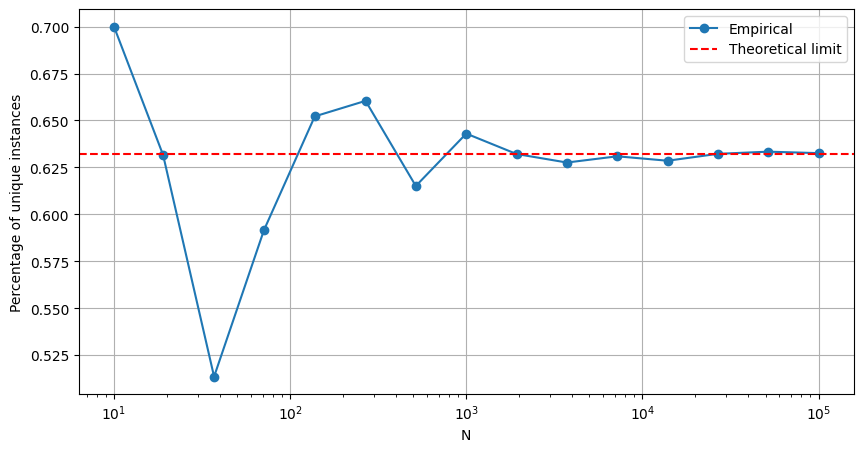

In [10]:
import numpy as np
import matplotlib.pyplot as plt


n = np.logspace(1, 5, 15, dtype=int)
proportions = []

for num in n:
    data = np.arange(num)
    bootstrap = np.random.choice(data, size=num, replace=True)

    unique_count = len(np.unique(bootstrap))
    proportions.append(unique_count / num)


plt.figure(figsize=(10, 5))
plt.plot(n, proportions, 'o-', label='Empirical')
plt.axhline(1 - 1/np.e, color='r', linestyle='--', label='Theoretical limit')
plt.xscale('log')
plt.xlabel('N')
plt.ylabel('Percentage of unique instances')
plt.legend()
plt.grid(True)
plt.show()

### Task 4: Hardness dataset

Given a hardness dataset (data/train.dat). The target property is stored in a 'property' column.

Features descirption is given in the original paper
https://arxiv.org/pdf/2304.12880


#### Part 1: (10 points)
- Perform EDA for the dataset

- Drop non-numerical columns

- Drop nearly collinear features ($R_p$ > 0.95) (done for you)

- Calculate a correlation matrix for the dataset

- Plot barplot for $R_p$(feature_i, target)

- Report top5 features that have the highest correlation with the target property



- What are these features? Explain why they have a strong correlation






In [11]:
import pandas as pd
import numpy as np

data = pd.read_csv('data/train.dat', sep = '\s+')


<>:4: SyntaxWarning: invalid escape sequence '\s'
<>:4: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2350/987270322.py:4: SyntaxWarning: invalid escape sequence '\s'
  data = pd.read_csv('data/train.dat', sep = '\s+')


In [12]:
def remove_collinear_features(x, threshold):

    # source: https://www.kaggle.com/code/oldwine357/removing-highly-correlated-features/notebook
    """
    Objective:
        Remove collinear features in a dataframe with a correlation coefficient
        greater than the threshold. Removing collinear features can help a model
        to generalize and improves the interpretability of the model.

    Inputs:
        x: features dataframe
        threshold: features with correlations greater than this value are removed

    Output:
        dataframe that contains only the non-highly-collinear features
    """

    # Calculate the correlation matrix
    corr_matrix = x.corr()
    iters = range(len(corr_matrix.columns) - 1)
    drop_cols = []

    # Iterate through the correlation matrix and compare correlations
    for i in iters:
        for j in range(i+1):
            item = corr_matrix.iloc[j:(j+1), (i+1):(i+2)]
            col = item.columns
            row = item.index
            val = abs(item.values)

            # If correlation exceeds the threshold
            if val >= threshold:
                # Print the correlated features and the correlation value
                #print(col.values[0], "|", row.values[0], "|", round(val[0][0], 2))
                drop_cols.append(col.values[0])

    # Drop one of each pair of correlated columns
    drops = set(drop_cols)
    x = x.drop(columns=drops)
    print('Removed Columns {}'.format(drops))
    return x

In [13]:
# drop collinear features

threshold = 0.95
X = remove_collinear_features(data.drop(['property', 'materials'], axis = 1), threshold)


Removed Columns {'Y', 'Gr', 'BV', 'GV', 'Br'}


In [14]:
pd.set_option('display.max_columns', 21)

In [15]:
data.drop(columns=['materials']).corr()

,property,D,Bv,Br,BV,Gv,Gr,GV,el,pr,Y,Fr,Rx,Rn,RW,Ax,An,AW,IEx,IEn,IEW
property,1.000000,0.258021,0.709283,0.707846,0.708699,0.869511,0.867554,0.868567,-0.373735,-0.595878,0.849059,0.656326,0.010693,-0.165277,-0.072826,0.053131,-0.530936,-0.145795,-0.088826,0.036807,-0.158371
D,0.258021,1.000000,0.601554,0.605496,0.603553,0.384561,0.375130,0.380175,-0.164039,0.108529,0.429273,0.040092,0.646642,0.085919,0.564243,0.901085,-0.243527,0.794581,-0.253096,0.136215,-0.216583
Bv,0.709283,0.601554,1.000000,0.999456,0.999851,0.885456,0.875579,0.881361,-0.427214,-0.245886,0.917535,0.359722,0.414456,-0.213729,0.213360,0.324443,-0.699027,0.071770,-0.141296,-0.043168,-0.209847
Br,0.707846,0.605496,0.999456,1.000000,0.999870,0.882529,0.873242,0.878727,-0.433954,-0.240502,0.915334,0.363587,0.415232,-0.213885,0.220526,0.326238,-0.698744,0.077853,-0.140362,-0.043719,-0.210622
BV,0.708699,0.603553,0.999851,0.999870,1.000000,0.883992,0.874401,0.880040,-0.430464,-0.242664,0.916438,0.362284,0.415113,-0.214010,0.217135,0.325257,-0.698844,0.074896,-0.140520,-0.043519,-0.209953
Gv,0.869511,0.384561,0.885456,0.882529,0.883992,1.000000,0.997811,0.999453,-0.473452,-0.594807,0.996317,0.510424,0.235479,-0.091988,0.096534,0.151694,-0.630151,-0.107889,-0.232706,-0.034336,-0.294727
Gr,0.867554,0.375130,0.875579,0.873242,0.874401,0.997811,1.000000,0.999431,-0.519512,-0.603288,0.994815,0.511214,0.232698,-0.083694,0.106866,0.142434,-0.624446,-0.108529,-0.240331,-0.034029,-0.303014
GV,0.868567,0.380175,0.881361,0.878727,0.880040,0.999453,0.999431,1.000000,-0.496613,-0.598583,0.996179,0.511038,0.234786,-0.088149,0.101627,0.147229,-0.627972,-0.108466,-0.236704,-0.034908,-0.299006
el,-0.373735,-0.164039,-0.427214,-0.433954,-0.430464,-0.473452,-0.519512,-0.496613,1.000000,0.287976,-0.496904,-0.138714,-0.216389,0.017402,-0.269369,-0.019188,0.435855,0.065961,0.185598,0.136868,0.297290
pr,-0.595878,0.108529,-0.245886,-0.240502,-0.242664,-0.594807,-0.603288,-0.598583,0.287976,1.000000,-0.551378,-0.284792,0.165443,-0.100838,0.130609,0.214081,0.304632,0.362917,0.254928,0.107500,0.302574


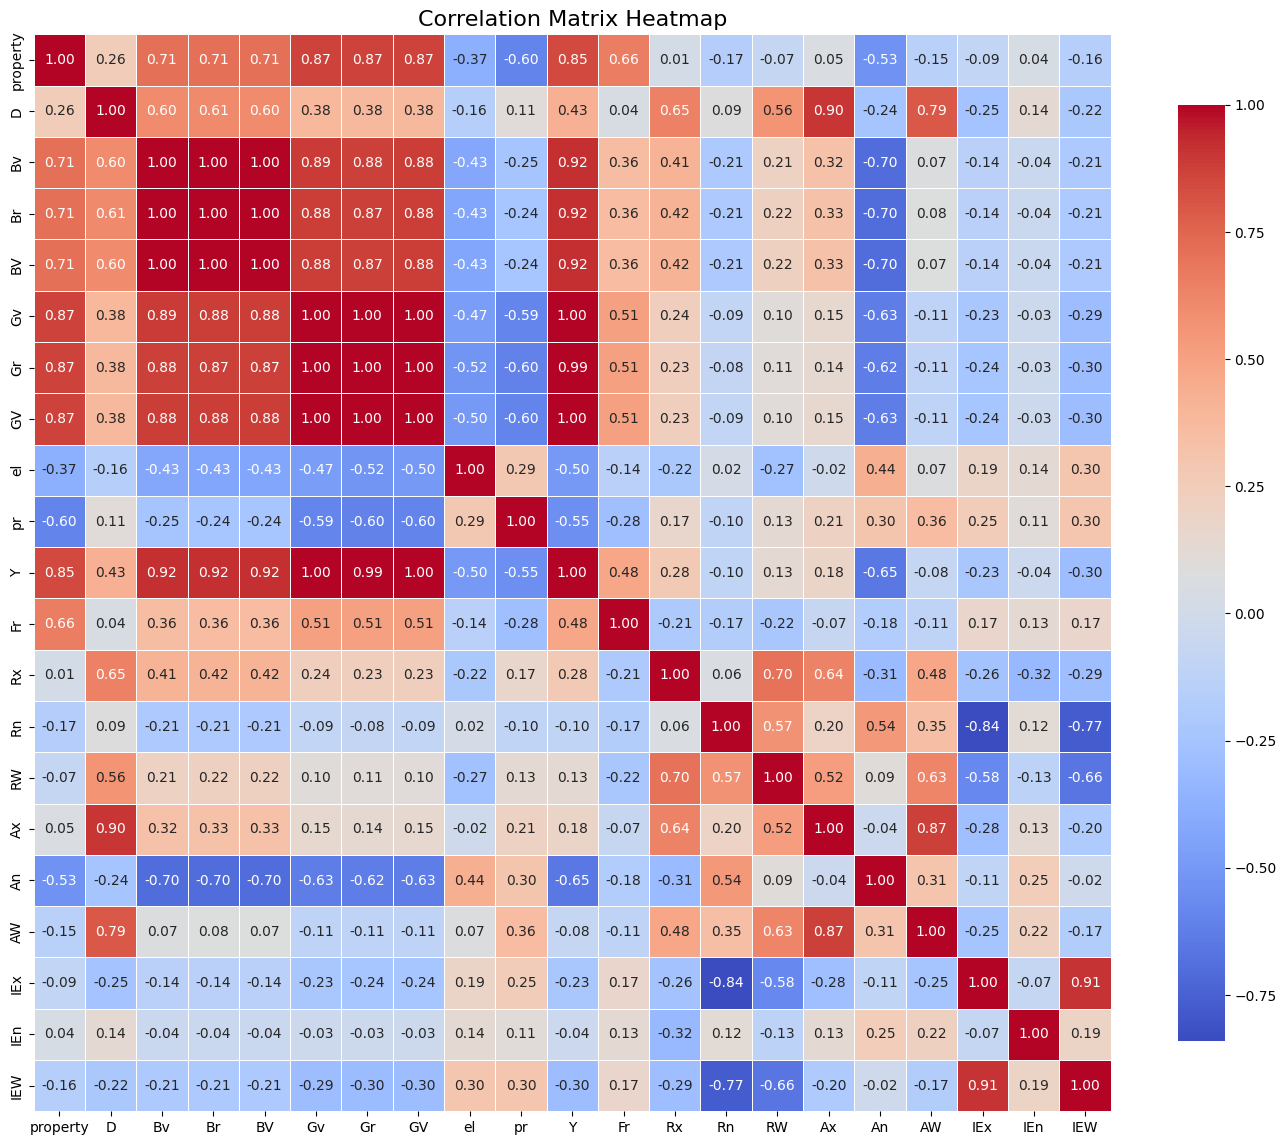

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = data.drop(columns=['materials']).corr()
plt.figure(figsize=(14, 12))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": .8}
)

plt.title('Correlation Matrix Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

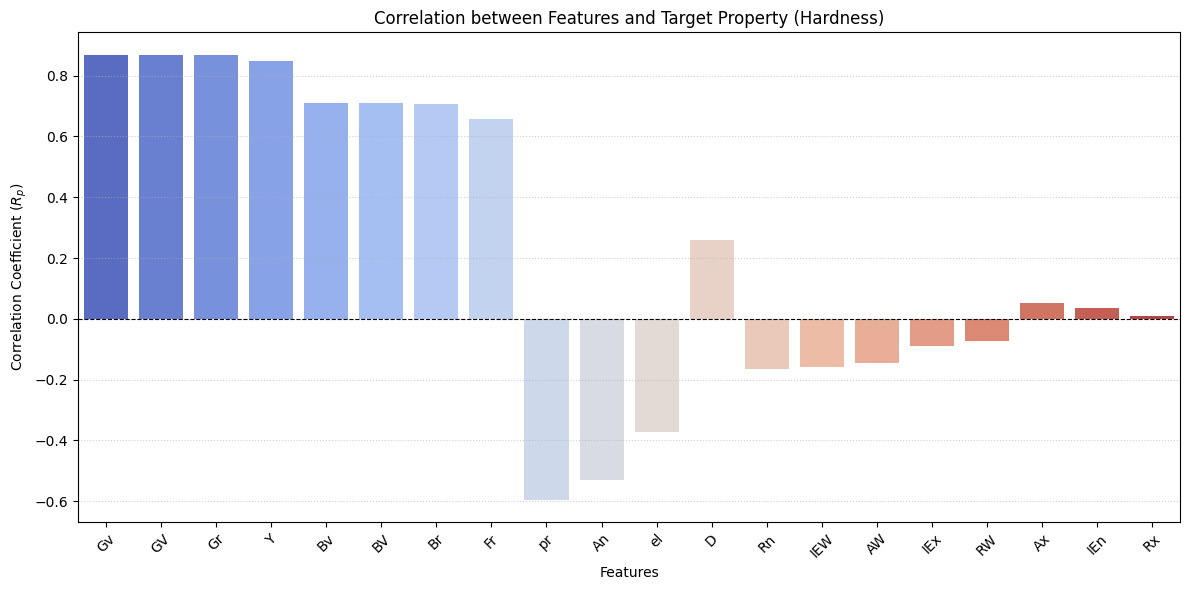

Top 5 features with the highest correlation with target:
Gv: absolute correlation = 0.8695
GV: absolute correlation = 0.8686
Gr: absolute correlation = 0.8676
Y: absolute correlation = 0.8491
Bv: absolute correlation = 0.7093


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


features_corr = data.drop(columns=['materials', 'property']).corrwith(data['property'])

sorted_corr = features_corr.reindex(features_corr.abs().sort_values(ascending=False).index)


plt.figure(figsize=(12, 6))
sns.barplot(x=sorted_corr.index, y=sorted_corr.values, palette='coolwarm', hue=sorted_corr.index, legend=False)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.xlabel('Features')
plt.ylabel('Correlation Coefficient ($R_p$)')
plt.title('Correlation between Features and Target Property (Hardness)')
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


top_5 = sorted_corr.abs().head(5)
print("Top 5 features with the highest correlation with target:")
for feature, val in top_5.items():
    sign = "+" if sorted_corr[feature] >= 0 else "-"
    print(f"{feature}: absolute correlation = {val:.4f}")

These features have highest correlation with the target because they directly represent the elastic moduli (Shear modulus G, Young's modulus Y, and Bulk modulus B) of the materials:

1. Shear modulus ($G_v, G_V, G_r$) measures the resistance of a material to shear deformation. Since plastic deformation and dislocation movement (which determine hardness) occur via shear processes, $G$ is physically the most critical descriptor for hardness.
2. Young's modulus ($Y$) reflects the overall stiffness and strength of chemical bonds in the crystal lattice. Stronger bonds make it harder to locally deform the material.
3. Bulk modulus ($B_v$) resists volume compression under pressure, correlating with the energy of chemical bonds. Materials with high bulk modulus strongly resist indentation.

#### Part 2: (20 points)

- Split your data set into train/test data splits with a ```test_size = 0.3```. Report a random seed used!
- Fit at least 4 different regression models (e.g. SVR, KRR, RF, KNN regressor, AdaBoost) and report test metrics

- For two these models perform a grid search optimization of hyperparameters using KFold cross validation

- Perform feature importance study. What features are the most important?

- Perform forward feature selection. Plot MSE (or other metric) vs. # features

- How many features are enough? Can we get a better perfomance with less features?

In [18]:
from sklearn.kernel_ridge import KernelRidge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
# from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from sklearn.neighbors import KNeighborsRegressor
import numpy as np




In [19]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.kernel_ridge import KernelRidge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_squared_error

X_hardness = remove_collinear_features(data.drop(['property', 'materials'], axis=1), threshold=0.95)

y_categories = pd.qcut(data['property'], q=5, labels=False, duplicates='drop')

X_temp, X_test, y_temp, y_test = train_test_split(
    X_hardness, data['property'],
    test_size=0.3,
    random_state=42,
    stratify=y_categories
)

y_temp_categories = pd.qcut(y_temp, q=5, labels=False, duplicates='drop')

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.2857,
    random_state=42,
    stratify=y_temp_categories
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

models = {
    'SVR': SVR(C=10, gamma='scale'),
    'KernelRidge': KernelRidge(alpha=1.0, kernel='rbf'),
    'RandomForest': RandomForestRegressor(n_estimators=300, random_state=42),
    'KNN': KNeighborsRegressor(n_neighbors=5)
}

print("Baseline Models Performance with Stratified Split:")
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds_val = model.predict(X_val_scaled)

    r2 = r2_score(y_val, preds_val)
    mse = mean_squared_error(y_val, preds_val)
    print(f"{name:12}  R2 Score: {r2:.4f}  MSE: {mse:.4f}")

Removed Columns {'Y', 'Gr', 'BV', 'GV', 'Br'}
Baseline Models Performance with Stratified Split:
SVR           R2 Score: 0.4410  MSE: 58.6989
KernelRidge   R2 Score: 0.0363  MSE: 101.2002
RandomForest  R2 Score: 0.5182  MSE: 50.5951
KNN           R2 Score: 0.5911  MSE: 42.9389


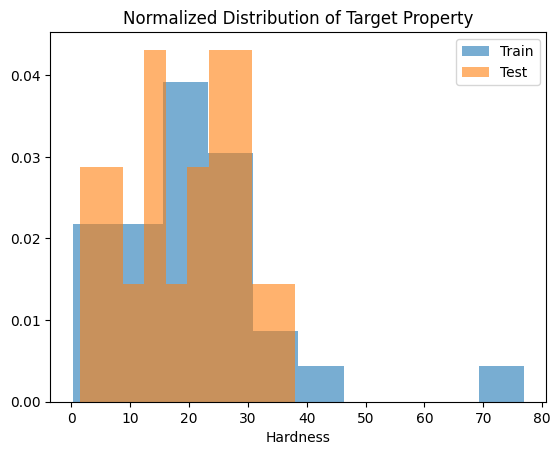

In [20]:
plt.hist(y_train, density=True, alpha=0.6, label='Train', bins=10)
plt.hist(y_test, density=True, alpha=0.6, label='Test', bins=10)
plt.xlabel('Hardness')
plt.title('Normalized Distribution of Target Property')
plt.legend()
plt.show()

In [21]:
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.kernel_ridge import KernelRidge
from sklearn.ensemble import RandomForestRegressor
import numpy as np

X_train_val = np.vstack([X_train, X_val])
y_train_val = np.concatenate([y_train, y_val])

scaler_cv = StandardScaler()
X_train_val_scaled = scaler_cv.fit_transform(X_train_val)
X_test_scaled = scaler_cv.transform(X_test)

kfold = KFold(n_splits=3, shuffle=True, random_state=42)

krr_param_grid = {
    'alpha': [0.01, 1.0],
    'kernel': ['rbf', 'laplacian'],
    'gamma': [0.01, 0.1]
}
krr_grid = GridSearchCV(KernelRidge(), param_grid=krr_param_grid, cv=kfold, scoring='r2', n_jobs=-1)
krr_grid.fit(X_train_val_scaled, y_train_val)

rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [5, None],
    'max_features': ['sqrt', None]
}
rf_grid = GridSearchCV(RandomForestRegressor(random_state=42), param_grid=rf_param_grid, cv=kfold, scoring='r2', n_jobs=-1)
rf_grid.fit(X_train_val_scaled, y_train_val)

print("Best KernelRidge parameters:", krr_grid.best_params_)
print(f"Best KernelRidge R2 (CV): {krr_grid.best_score_:.4f}")
print("\nBest RF parameters:", rf_grid.best_params_)
print(f"Best RF R2 (CV): {rf_grid.best_score_:.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


Best KernelRidge parameters: {'alpha': 1.0, 'gamma': 0.01, 'kernel': 'rbf'}
Best KernelRidge R2 (CV): 0.2489

Best RF parameters: {'max_depth': 5, 'max_features': None, 'n_estimators': 100}
Best RF R2 (CV): 0.2567


In [22]:
# get r2_score and MSE

In [23]:

best_model = krr_grid.best_estimator_ if krr_grid.best_score_ > rf_grid.best_score_ else rf_grid.best_estimator_
print(f"Selected best model: {best_model}")


preds_test = best_model.predict(X_test_scaled)

test_r2 = r2_score(y_test, preds_test)
test_mse = mean_squared_error(y_test, preds_test)

print(f"\nPerformance on Test Set:")
print(f"R2 Score: {test_r2:.4f}")
print(f"MSE: {test_mse:.4f}")

Selected best model: RandomForestRegressor(max_depth=5, max_features=None, random_state=42)

Performance on Test Set:
R2 Score: 0.7368
MSE: 27.6535


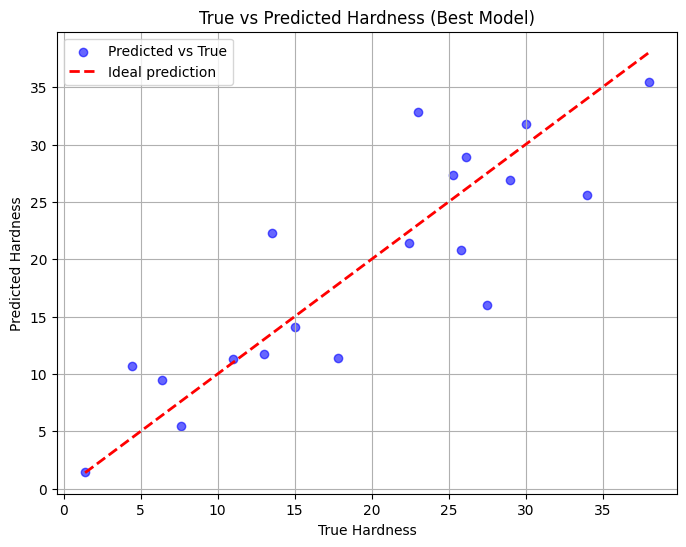

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, preds_test, color='blue', alpha=0.6, label='Predicted vs True')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Ideal prediction')
plt.xlabel('True Hardness')
plt.ylabel('Predicted Hardness')
plt.title('True vs Predicted Hardness (Best Model)')
plt.legend()
plt.grid(True)
plt.show()

In [25]:
from mlxtend.feature_selection import SequentialFeatureSelector as SFS

X_temp_hard, X_test_hard, y_temp_hard, y_test_hard = train_test_split(X, data['property'], test_size=0.3, random_state=0)
y_train_hardness, y_val_hardness = train_test_split(y_temp_hard, test_size=0.2857, random_state=0)

sfs = SFS(
    rf_grid.best_estimator_,
    k_features='best',
    forward=True,
    floating=False,
    scoring='neg_mean_squared_error',
    cv=3,
    n_jobs=-1
)


sfs = sfs.fit(X_train_scaled, y_train_hardness)

print("Selected Features:", sfs.k_feature_names_)
print("Best CV MSE:", -sfs.k_score_)

Selected Features: ('1', '6', '8')
Best CV MSE: 105.26159175532825


In [26]:

from sklearn.model_selection import cross_val_score

remaining_features = list(X.columns)
selected_features = []
best_scores_by_step = []

for i in range(len(X.columns)):
    step_scores = []
    for feature in remaining_features:
        candidate_features = selected_features + [feature]

        X_subset = X_train_scaled[:, [X.columns.get_loc(f) for f in candidate_features]]
        scores = cross_val_score(rf_grid.best_estimator_, X_subset, y_train, cv=3, scoring='neg_mean_squared_error')
        step_scores.append((np.mean(scores), feature))

    step_scores.sort(reverse=True)
    best_score, best_feature = step_scores[0]

    selected_features.append(best_feature)
    remaining_features.remove(best_feature)
    best_scores_by_step.append(-best_score)

    print(f"Step {i+1}: Added {best_feature:10} | CV MSE: {-best_score:.4f}")

Step 1: Added Gv         | CV MSE: 115.9694
Step 2: Added pr         | CV MSE: 84.0374
Step 3: Added An         | CV MSE: 81.6848
Step 4: Added Rn         | CV MSE: 81.2371
Step 5: Added IEx        | CV MSE: 82.1876
Step 6: Added IEn        | CV MSE: 82.5494
Step 7: Added Bv         | CV MSE: 82.7812
Step 8: Added RW         | CV MSE: 83.9359
Step 9: Added D          | CV MSE: 86.4885
Step 10: Added Ax         | CV MSE: 87.2409
Step 11: Added AW         | CV MSE: 87.7015
Step 12: Added IEW        | CV MSE: 89.6773
Step 13: Added Fr         | CV MSE: 97.3680
Step 14: Added Rx         | CV MSE: 103.8602
Step 15: Added el         | CV MSE: 112.5870


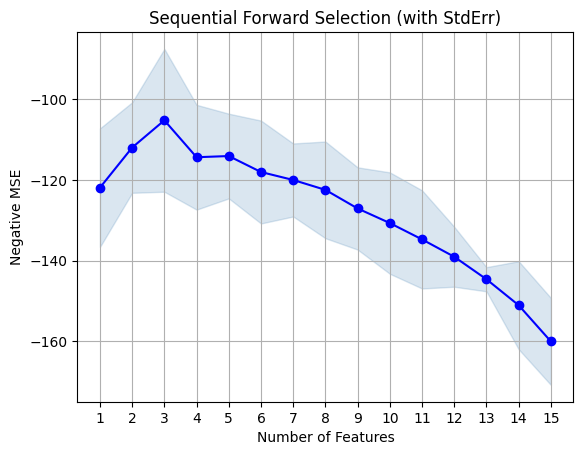

In [27]:
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs

fig = plot_sfs(sfs.get_metric_dict(), kind='std_err')
plt.title('Sequential Forward Selection (with StdErr)')
plt.ylabel('Negative MSE')
plt.xlabel('Number of Features')
plt.grid(True)
plt.show()

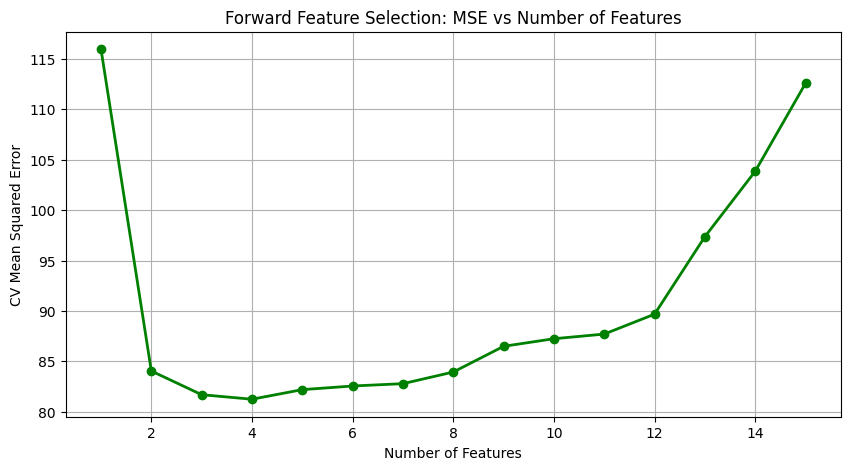

In [28]:

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(best_scores_by_step) + 1), best_scores_by_step, 'o-', color='green', lw=2)
plt.xlabel('Number of Features')
plt.ylabel('CV Mean Squared Error')
plt.title('Forward Feature Selection: MSE vs Number of Features')
plt.grid(True)
plt.show()

In [29]:
# refit model on the selected features

In [30]:

optimal_n = 5
optimal_features = selected_features[:optimal_n]

opt_feature_indices = [X.columns.get_loc(f) for f in optimal_features]

X_train_opt = X_train_scaled[:, opt_feature_indices]
X_test_opt = X_test_scaled[:, opt_feature_indices]


refitted_model = rf_grid.best_estimator_
refitted_model.fit(X_train_opt, y_train)
preds_opt = refitted_model.predict(X_test_opt)

In [31]:

opt_r2 = r2_score(y_test, preds_opt)
opt_mse = mean_squared_error(y_test, preds_opt)
print(f"Refitted RandomForest with {optimal_n} features - R2: {opt_r2:.4f}, MSE: {opt_mse:.4f}")

Refitted RandomForest with 5 features - R2: 0.6629, MSE: 35.4255


In [32]:
# plot y_test vs. predictions

In [33]:
# What are the features?

In [34]:

print(f"Selected optimal features: {optimal_features}")
refit_r2 = r2_score(y_test, preds_opt)
refit_mse = mean_squared_error(y_test, preds_opt)
print(f"\nRefitted Model Metrics:")
print(f"R2 Score: {refit_r2:.4f}")
print(f"MSE: {refit_mse:.4f}")

Selected optimal features: ['Gv', 'pr', 'An', 'Rn', 'IEx']

Refitted Model Metrics:
R2 Score: 0.6629
MSE: 35.4255


In [35]:

custom_features = ['Gv', 'pr', 'An', 'Bv', 'Fr', 'D']
print(f"Custom selected features: {custom_features}")

custom_feature_indices = [X.columns.get_loc(f) for f in custom_features]

X_train_custom = X_train_scaled[:, custom_feature_indices]
X_test_custom = X_test_scaled[:, custom_feature_indices]

custom_model = rf_grid.best_estimator_
custom_model.fit(X_train_custom, y_train)
preds_custom = custom_model.predict(X_test_custom)

custom_r2 = r2_score(y_test, preds_custom)
custom_mse = mean_squared_error(y_test, preds_custom)

print(f"\nResults with custom 6 features:")
print(f"R2 Score: {custom_r2:.4f}")
print(f"MSE: {custom_mse:.4f}")

Custom selected features: ['Gv', 'pr', 'An', 'Bv', 'Fr', 'D']

Results with custom 6 features:
R2 Score: 0.7188
MSE: 29.5472


### Task 6: MLP Classifier (10 points)
- Train an MLPClassifier

- Plot the decision boundary for the trained model

- Achieve at least 95% accuracy on the test set

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split


X, y = make_moons(n_samples=500, noise=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y)


In [44]:

mlp = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation='relu',
    max_iter=1000,
    random_state=42
)

mlp.fit(X_train, y_train)
test_acc = mlp.score(X_test, y_test)
print(f"MLP Classifier Test Accuracy: {test_acc * 100:.2f}%")

MLP Classifier Test Accuracy: 100.00%


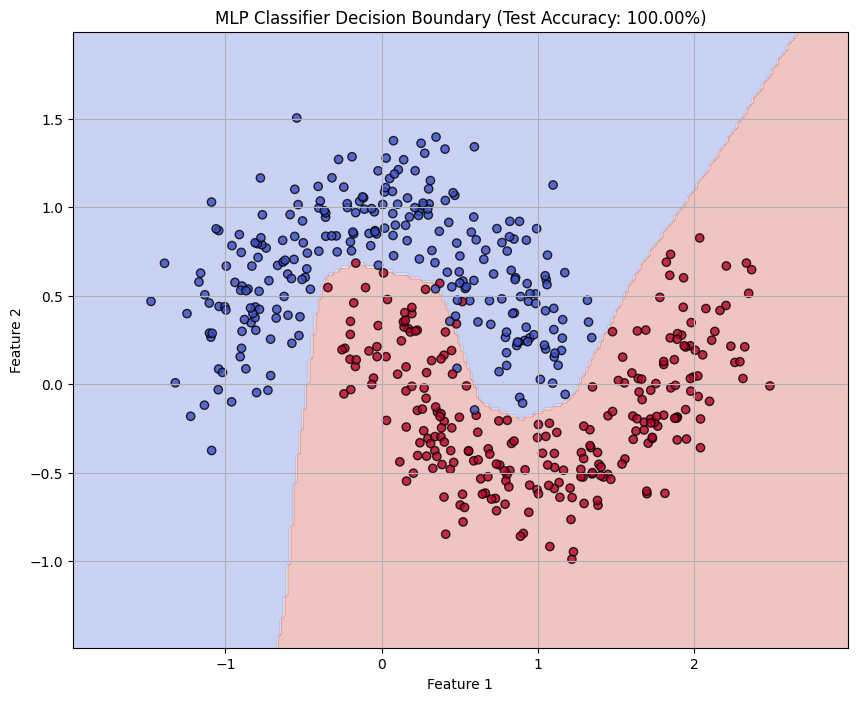

In [45]:
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))

Z = mlp.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 8))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap='coolwarm', alpha=0.8)
plt.title(f'MLP Classifier Decision Boundary (Test Accuracy: {test_acc * 100:.2f}%)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()

In [48]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_train_pred = mlp.predict(X_train)
y_test_pred = mlp.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Train Set Accuracy: {train_accuracy * 100:.2f}%")
print(f"Test Set Accuracy: {test_accuracy * 100:.2f}%")



Train Set Accuracy: 98.13%
Test Set Accuracy: 100.00%
